# 02 — Treinar TODOS os modelos em sequência

Roda todos os experimentos (ou um subconjunto), de forma resiliente: se um
modelo falhar ou a sessão cair, os demais continuam e o erro fica no
`status.json`. Ao final, consolida os resultados e gera a tabela comparativa.

⚠️ Treino completo é demorado. Considere começar com `SMOKE_TEST=True`.

## 1. Montar o Google Drive e localizar o projeto

⚠️ **Suba o PROJETO INTEIRO para o Drive**, não só a pasta `Data`. A pasta
no Drive (por padrão `/content/drive/MyDrive/Fato_Tese_Ruido`) precisa conter:

```
Fato_Tese_Ruido/
├── requirements.txt
├── src/ftr/...        ← o módulo 'ftr' (sem isto: No module named 'ftr')
├── configs/
├── scripts/
└── Data/dataset_FINAL.json
```

A célula abaixo **localiza a pasta automaticamente** (procurando por
`src/ftr`) e mostra um checklist do que está presente/faltando.

In [2]:
!nvidia-smi

Tue Jun  2 18:03:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   31C    P0             47W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
import os, sys, glob

# Monta o Drive (somente no Colab).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print('Não está no Colab — usando caminho local.')


def _looks_like_project(p):
    return os.path.isdir(os.path.join(p, 'src', 'ftr'))


def _autodetect_root():
    candidates = ['/content/drive/MyDrive/Fato_Tese_Ruido']
    # procura qualquer pasta com src/ftr dentro do MyDrive (2 níveis)
    for base in ('/content/drive/MyDrive', '/content/drive/My Drive'):
        candidates += glob.glob(os.path.join(base, '**', 'src', 'ftr'), recursive=False)
        candidates += [os.path.dirname(os.path.dirname(p))
                       for p in glob.glob(os.path.join(base, '*', 'src', 'ftr'))]
    for c in candidates:
        if c and _looks_like_project(c):
            return c
    return candidates[0] if candidates else os.getcwd()


PROJECT_ROOT = _autodetect_root() if IN_COLAB else os.getcwd()
os.environ['FTR_PROJECT_ROOT'] = PROJECT_ROOT
if os.path.join(PROJECT_ROOT, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(PROJECT_ROOT, 'src'))
print('PROJECT_ROOT =', PROJECT_ROOT)

# Itens OBRIGATÓRIOS (o código + os dados).
required = {'src/ftr': 'pasta (módulo ftr)', 'configs': 'pasta',
            'scripts': 'pasta', 'Data/dataset_FINAL.json': 'dataset'}
# Itens OPCIONAIS (o Drive às vezes converte .txt/.xlsx p/ Google Docs/Sheets,
# removendo a extensão — sem problema, instalamos as deps explicitamente abaixo).
optional = {'requirements.txt': 'arquivo (opcional)'}
print('\nChecklist da pasta do projeto:')
missing = []
for rel, kind in required.items():
    ok = os.path.exists(os.path.join(PROJECT_ROOT, rel))
    print(f'  [{"OK" if ok else "FALTA"}] {rel}  ({kind})')
    if not ok:
        missing.append(rel)
for rel, kind in optional.items():
    ok = os.path.exists(os.path.join(PROJECT_ROOT, rel))
    print(f'  [{"OK" if ok else "--"}] {rel}  ({kind})')
if missing:
    raise SystemExit('\nFALTAM itens OBRIGATÓRIOS acima. Suba a PASTA INTEIRA do '
                     'projeto para o Drive (não só Data/).')
print('\nOK — itens obrigatórios presentes. (requirements.txt é opcional.)')

Mounted at /content/drive
PROJECT_ROOT = /content/drive/MyDrive/Fato_Tese_Ruido

Checklist da pasta do projeto:
  [OK] src/ftr  (pasta (módulo ftr))
  [OK] configs  (pasta)
  [OK] scripts  (pasta)
  [OK] Data/dataset_FINAL.json  (dataset)
  [--] requirements.txt  (arquivo (opcional))

OK — itens obrigatórios presentes. (requirements.txt é opcional.)


## 2. Instalar dependências

Instala as bibliotecas explicitamente (não depende do `requirements.txt`, que o
Drive às vezes converte para Google Docs). torch já vem no Colab.

In [5]:
if IN_COLAB:
    !pip install -q 'transformers==4.48.3' 'datasets==3.3.0' 'scikit-learn==1.6.1' \
        evaluate sentencepiece sacremoses 'accelerate>=1.3.0' openpyxl seaborn pyarrow
    print('\nDependências instaladas.')
else:
    print('Local: instale com  pip install -r requirements.txt')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 139.5 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 484.9/484.9 kB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 83.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 66.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 120.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.12.0 which is incompatible.

Dependências instaladas.


## 3. Verificar GPU, ambiente e caminhos

In [6]:
import torch
from ftr.env import describe_environment, get_paths
print('CUDA disponível:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
import json
print(json.dumps(describe_environment(), indent=2, ensure_ascii=False))

CUDA disponível: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
{
  "in_colab": true,
  "drive_mounted": true,
  "project_root": "/content/drive/MyDrive/Fato_Tese_Ruido",
  "root_exists": true,
  "raw_dataset": "/content/drive/MyDrive/Fato_Tese_Ruido/Data/dataset_FINAL.json",
  "raw_dataset_exists": true,
  "python": "3.12.13",
  "platform": "linux"
}


## 4. Verificar que o dataset está no lugar

In [7]:
paths = get_paths()
print('Dataset bruto:', paths.raw_dataset)
assert paths.raw_dataset.exists(), (
    f'Dataset não encontrado em {paths.raw_dataset}. '
    'Suba Data/dataset_FINAL.json para o Drive.')
print('OK — dataset encontrado (%.1f MB).' % (paths.raw_dataset.stat().st_size/1e6))

Dataset bruto: /content/drive/MyDrive/Fato_Tese_Ruido/Data/dataset_FINAL.json
OK — dataset encontrado (259.0 MB).


## 5. Preparar dados

Aplica limpeza, anonimização e **split por documento** (anti-leakage).
O script agrupa fragmentos do mesmo processo judicial via OAB/email do
advogado e garante que nenhum fragmento aparece em treino E teste.
Ao final, imprime o vazamento estimado — deve ser 0.00%.

In [8]:
!cd "{PROJECT_ROOT}" && python -W all scripts/01_prepare_data.py --config configs/_base.yaml

2026-06-02 18:04:34.100404: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-02 18:04:34.131881: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.12/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))
/usr/local/lib/python3.12/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' depreca

## 6. Parâmetros

In [9]:
SMOKE_TEST        = False  # @param {type:"boolean"} — True = 5 steps por modelo (teste rápido)
REPRODUCTIONS_ONLY = False  # @param {type:"boolean"} — só os 4 modelos originais
# Alerta de convergência: se os últimos CONVERGENCE_WINDOW modelos
# estiverem dentro de CONVERGENCE_THRESHOLD de f1_macro, pausa e pergunta.
# No Colab (sem terminal interativo) a flag --non-interactive continua automaticamente.
CONVERGENCE_THRESHOLD = 0.005  # @param {type:"number"}
CONVERGENCE_WINDOW    = 3      # @param {type:"integer"}

## 7. Validar código antes de treinar

Confirma que os arquivos corretos estão carregados.
**Execute esta célula antes de qualquer treino** — ela detecta se há
versões antigas dos módulos e avisa antes de gastar créditos de GPU.

In [10]:
import inspect, sys, importlib

# Recarrega módulos para garantir que o Drive foi lido (não cache)
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith('ftr'):
        del sys.modules[mod_name]

import ftr.evaluate, ftr.data, ftr.train

checks = {
    'evaluate.py (bug tuple-output)': ('Dataset SEM labels', inspect.getsource(ftr.evaluate._predict_truncation)),
    'data.py (split por documento)':  ('GroupShuffleSplit',   inspect.getsource(ftr.data.split_dataset)),
    'train.py (import os)':           ('import os',           inspect.getsource(ftr.train)),
}

all_ok = True
for desc, (keyword, src) in checks.items():
    ok = keyword in src
    status = 'OK' if ok else 'FALHOU — arquivo antigo no Drive!'
    print(f'  [{status}] {desc}')
    if not ok: all_ok = False

if not all_ok:
    raise SystemExit('Corrija os arquivos acima antes de treinar. '
                     'Suba novamente a pasta src/ do projeto local para o Drive.')
print()
print('Tudo OK — pode prosseguir com o treino.')

  [OK] evaluate.py (bug tuple-output)
  [OK] data.py (split por documento)
  [OK] train.py (import os)

Tudo OK — pode prosseguir com o treino.


## 8. Rodar tudo

In [11]:
extra = ''
if SMOKE_TEST:        extra += ' --max-steps 5'
if REPRODUCTIONS_ONLY: extra += ' --reproductions-only'
extra += f' --convergence-threshold {CONVERGENCE_THRESHOLD}'
extra += f' --window {CONVERGENCE_WINDOW}'
extra += ' --non-interactive'  # Colab nao tem terminal interativo

!cd "{PROJECT_ROOT}" && python scripts/run_all.py {extra}

Modelos a treinar (8): ['bertimbau_base', 'bertimbau_large', 'longformer_pt', 'mbert', 'mdeberta_v3', 'roberta_crawlpt', 'roberta_lexpt', 'xlmr']

>>> bertimbau_base  (neuralmind/bert-base-portuguese-cased)
2026-06-02 18:06:02.005322: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-02 18:06:02.037812: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-02 18:06:08,919 INFO === Iniciando experimento bertimbau_base (run 58c42104) ===
2026-06-02 18:06:10,145 INFO Tamanhos: {'train': 20377, '

## 9. Reavaliar experimentos com métricas suspeitas

Se os resultados no teste estiverem ~0.31 (acaso para 3 classes), significa
que o experimento foi gerado com código antigo. Esta célula detecta e corrige
**sem re-treinar** — apenas recarrega o `best_model` salvo e reavalia.

In [12]:
import json
from ftr.registry import collect_experiments
from ftr.config import load_config
from ftr.evaluate import evaluate_from_dir

REEVAL_THRESHOLD = 0.5  # f1_macro abaixo disso = resultado suspeito

runs = collect_experiments(paths.experiments)
suspicious = []
for r in runs:
    if r.get('status') != 'completed': continue
    tm = r.get('test_metrics') or {}
    f1 = tm.get('f1_macro', 0) if tm else 0
    if f1 < REEVAL_THRESHOLD:
        suspicious.append(r)

if not suspicious:
    print('Nenhum resultado suspeito encontrado.')
else:
    print(f'{len(suspicious)} experimento(s) com f1_macro < {REEVAL_THRESHOLD} — reavaliando...')
    for r in suspicious:
        exp_dir = paths.experiments / r['run_dir']
        cfg_path = exp_dir / 'config_snapshot.yaml'
        if not cfg_path.exists():
            print(f'  {r["experiment_id"]}: config_snapshot.yaml nao encontrado — pulando')
            continue
        try:
            cfg = load_config(cfg_path, configs_dir=paths.configs)
            m = evaluate_from_dir(exp_dir, cfg, paths)
            print(f'  {r["experiment_id"]:20s}  f1_macro={m["f1_macro"]:.4f}  acc={m["accuracy"]:.4f}')
        except Exception as e:
            print(f'  {r["experiment_id"]}: ERRO — {e}')

Nenhum resultado suspeito encontrado.


## 10. Consolidar e ver a tabela comparativa

In [13]:
!cd "{PROJECT_ROOT}" && python scripts/04_consolidate.py
import pandas as pd
df = pd.read_csv(paths.results / 'comparison_table.csv')
df[['experiment_id','f1_macro','accuracy','mcc','roc_auc_macro_ovr']].sort_values('f1_macro', ascending=False)

Execuções encontradas: 8 | com métricas de teste: 7
JSON consolidado: /content/drive/MyDrive/Fato_Tese_Ruido/results/consolidated_results.json
Tabela: {'csv': '/content/drive/MyDrive/Fato_Tese_Ruido/results/comparison_table.csv', 'xlsx': '/content/drive/MyDrive/Fato_Tese_Ruido/results/comparison_table.xlsx'}
  gráfico: /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/comparison/comparison_f1_macro_pt.png
  gráfico: /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/comparison/comparison_f1_macro_en.png
  gráfico: /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/comparison/comparison_accuracy_pt.png
  gráfico: /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/comparison/comparison_accuracy_en.png
  gráfico: /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/comparison/comparison_mcc_pt.png
  gráfico: /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/comparison/comparison_mcc_en.png
  gráfico: /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/comparison

,experiment_id,f1_macro,accuracy,mcc,roc_auc_macro_ovr
0,bertimbau_large,0.990128,0.990231,0.985346,0.999154
1,bertimbau_base,0.989736,0.989840,0.984779,0.999158
2,roberta_lexpt,0.989730,0.989840,0.984757,0.998734
3,xlmr,0.989327,0.989449,0.984167,0.998807
4,roberta_crawlpt,0.987775,0.987886,0.981870,0.998934
5,mbert,0.986578,0.986714,0.980063,0.998746
6,mdeberta_v3,0.984225,0.984369,0.976576,0.998476


## 11. Gráficos comparativos

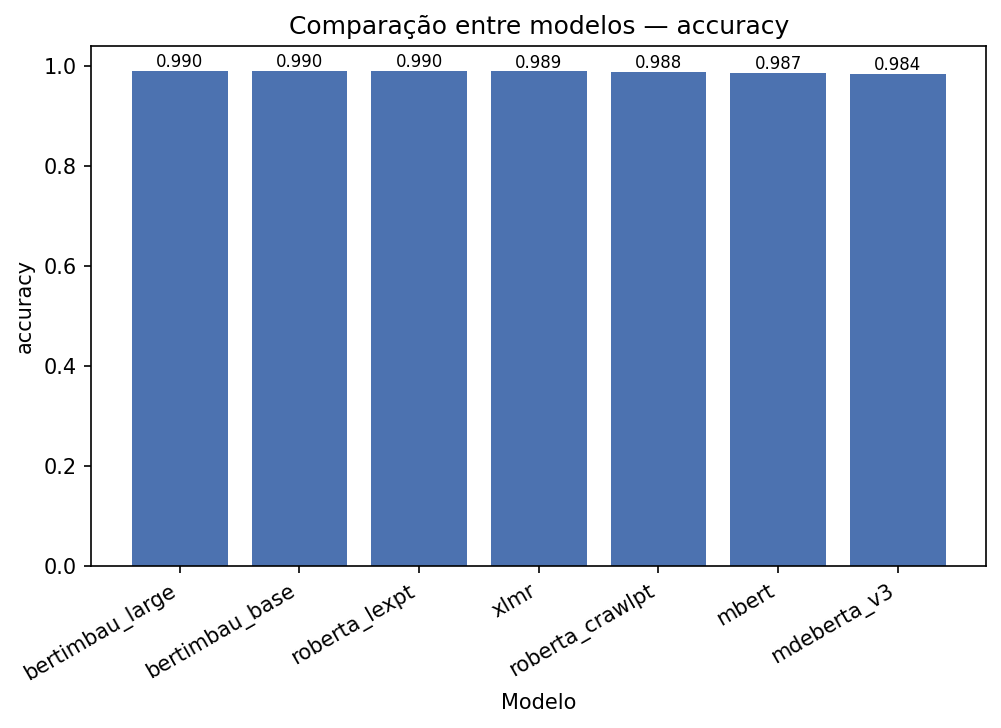

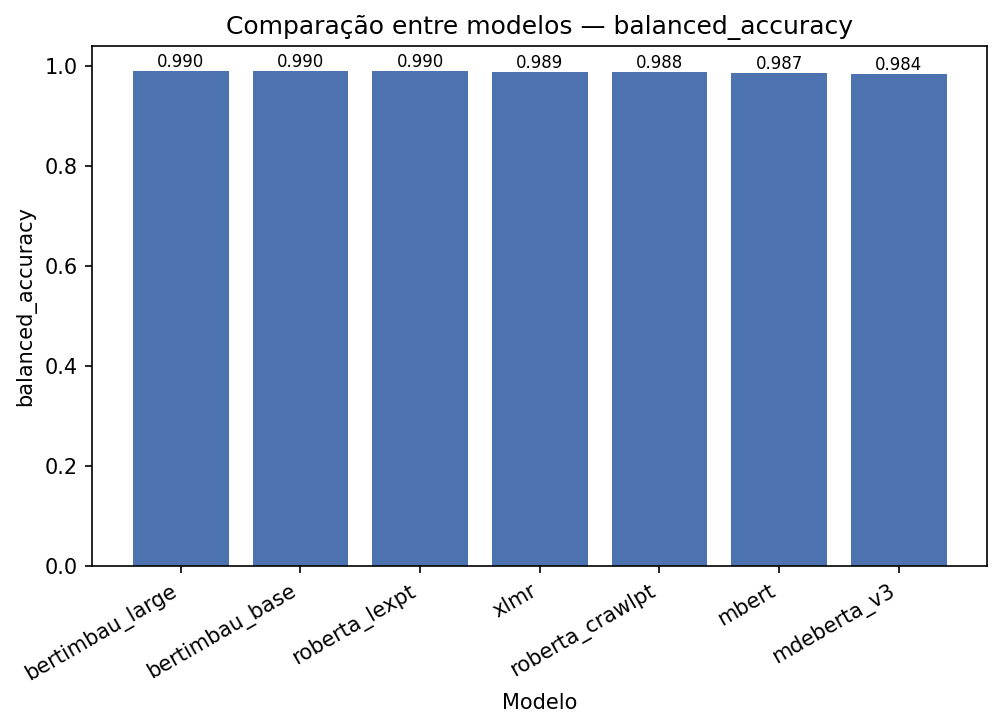

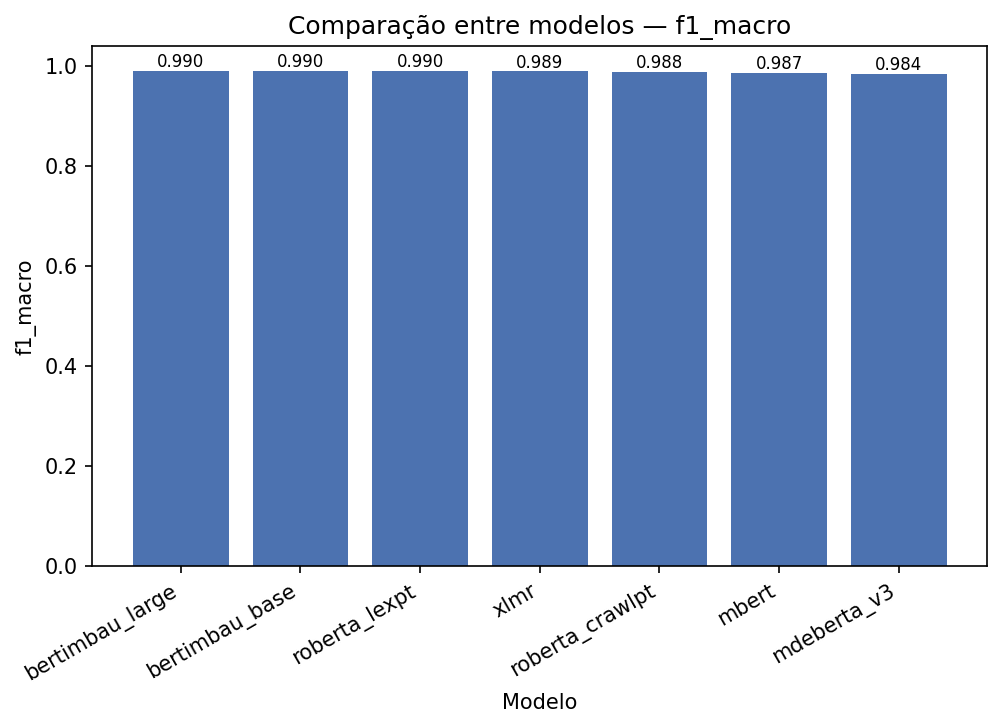

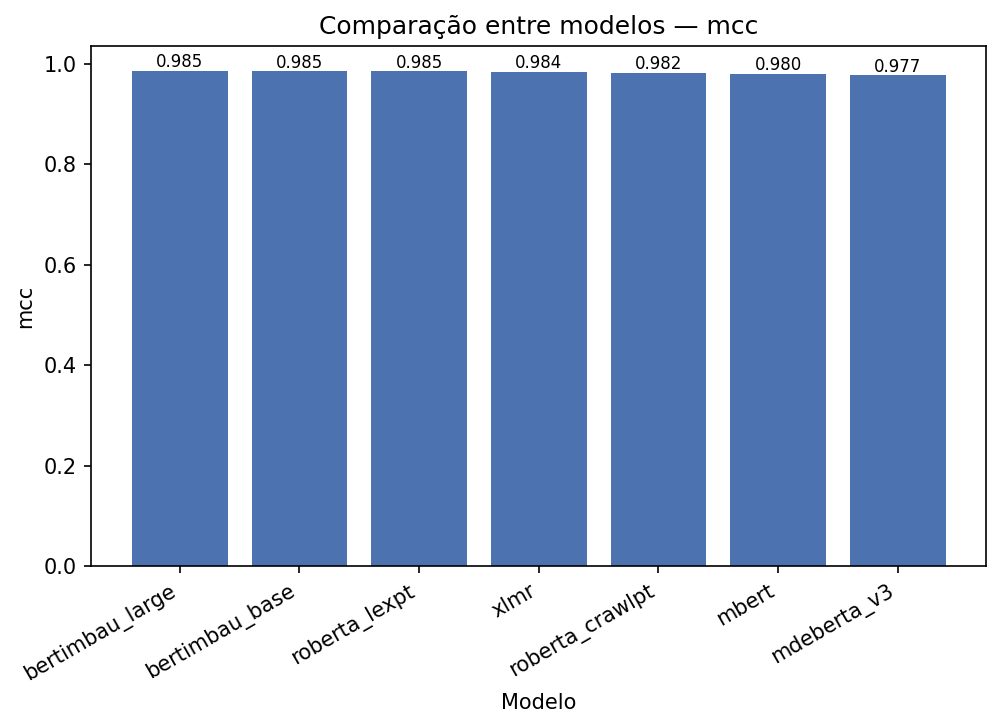

In [14]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(str(paths.results_figures / 'comparison' / '*_pt.png'))):
    display(Image(f))

## 12. Baixar os resultados

Os artefatos já estão no seu Drive (em `experiments/`, `results/`, `reports/`).
Baixe essas pastas do Drive e coloque localmente na sua IDE para análise.

## 13. Encerrar a sessão do Colab

Após confirmar que tudo foi salvo no Drive, esta célula aguarda 5 minutos
(tempo de segurança para o Drive sincronizar) e então encerra a sessão
automaticamente, evitando consumo de créditos desnecessários.

**Só rode esta célula quando tiver certeza de que todos os resultados
foram salvos no Drive.**

In [ ]:
import time

WAIT_MINUTES = 5  # @param {type:"integer"}
AUTO_SHUTDOWN = True  # @param {type:"boolean"}

if AUTO_SHUTDOWN and IN_COLAB:
    print(f'Aguardando {WAIT_MINUTES} min para o Drive sincronizar...')
    for remaining in range(WAIT_MINUTES * 60, 0, -30):
        print(f'  Encerrando em {remaining//60}m{remaining%60:02d}s...')
        time.sleep(30)
    print('Encerrando sessão do Colab.')
    from google.colab import runtime
    runtime.unassign()
else:
    print('AUTO_SHUTDOWN=False ou fora do Colab — sessão mantida.')

In [17]:
# Roda a análise de erros para todos os modelos de uma vez
import os, sys
sys.path.insert(0, '/content/drive/MyDrive/Fato_Tese_Ruido/src')
os.environ['FTR_PROJECT_ROOT'] = '/content/drive/MyDrive/Fato_Tese_Ruido'

os.chdir('/content/drive/MyDrive/Fato_Tese_Ruido')

from ftr.registry import collect_experiments
from ftr.env import get_paths

paths = get_paths()
runs = [r for r in collect_experiments(paths.experiments) if r.get('status') == 'completed']

for r in sorted(runs, key=lambda r: r.get('started_at', '')):
    eid = r['experiment_id']
    print(f"Analisando {eid}...")
    os.system(f"python scripts/06_error_analysis.py --exp {eid} --threshold 0.85 --top 20")
    print()


Analisando bertimbau_base...

Analisando bertimbau_large...

Analisando mbert...

Analisando mdeberta_v3...

Analisando roberta_crawlpt...

Analisando roberta_lexpt...

Analisando xlmr...



In [19]:
import subprocess, os

os.chdir('/content/drive/MyDrive/Fato_Tese_Ruido')

from ftr.registry import collect_experiments
from ftr.env import get_paths

paths = get_paths()
runs = [r for r in collect_experiments(paths.experiments) if r.get('status') == 'completed']

for r in sorted(runs, key=lambda r: r.get('started_at', '')):
    eid = r['experiment_id']
    print(f"\n{'='*50}")
    print(f"Analisando {eid}...")
    result = subprocess.run(
        ['python', 'scripts/06_error_analysis.py', '--exp', eid, '--threshold', '0.85', '--top', '20'],
        capture_output=True, text=True
    )
    if result.stdout:
        print(result.stdout)
    if result.stderr:
        print("STDERR:", result.stderr[-500:])  # últimas 500 chars do erro



Analisando bertimbau_base...

=== Análise de Erros — bertimbau_base ===
Total de erros de alta confiança (≥85%): 23
Pares de erro mais frequentes:
  fato → pred tese: 15
  tese → pred fato: 7
  tese → pred ruido: 1

Artefatos salvos em: /content/drive/MyDrive/Fato_Tese_Ruido/experiments/bertimbau_base__20260602_180608__58c42104/error_analysis
  high_confidence_errors.json
  error_analysis_report.md  ← copie para o paper


Analisando bertimbau_large...

=== Análise de Erros — bertimbau_large ===
Total de erros de alta confiança (≥85%): 21
Pares de erro mais frequentes:
  fato → pred tese: 13
  tese → pred fato: 7
  tese → pred ruido: 1

Artefatos salvos em: /content/drive/MyDrive/Fato_Tese_Ruido/experiments/bertimbau_large__20260602_181208__e9f4e659/error_analysis
  high_confidence_errors.json
  error_analysis_report.md  ← copie para o paper


Analisando mbert...

=== Análise de Erros — mbert ===
Total de erros de alta confiança (≥85%): 29
Pares de erro mais frequentes:
  tese → pred f

In [20]:
# Ensemble top-3
import subprocess, os
os.chdir('/content/drive/MyDrive/Fato_Tese_Ruido')
result = subprocess.run(
    ['python', 'scripts/05_ensemble.py', '--top', '3'],
    capture_output=True, text=True
)
print(result.stdout)
if result.stderr: print("STDERR:", result.stderr[-300:])


Top-3 por f1_macro: ['bertimbau_large', 'bertimbau_base', 'roberta_lexpt']

=== Ensemble (bertimbau_large, bertimbau_base, roberta_lexpt) ===
  f1_macro: 0.9905
  f1_weighted: 0.9906
  accuracy: 0.9906
  mcc: 0.9859
  roc_auc_macro_ovr: 0.9994

Resultados salvos em: /content/drive/MyDrive/Fato_Tese_Ruido/results/ensemble/ensemble_bertimba_bertimba_roberta_

